# Protostar — Final pipeline: verified data, final missing-data policy, forecasts

This notebook consolidates Experiments 1–5b into one reproducible pipeline. It contains only decisions that the earlier experiments tested.

**Final data policy**

| Target | History labels used by the forecasters | Evidence (Exp 5b, matched backtest) |
|---|---|---|
| Avg Temp | ≤30 missing days with climatological infill, then homogenised to each city's current station level | −0.4% MAE, P(better) = 0.997 |
| CDD | same as Avg Temp | −1.0% MAE, P(better) = 1.00 |
| Max Tmax | strict ≤10 missing days, official values | alternatives within 0.003 °F |
| Precipitation | strict ≤10 missing days, official values | every adjustment neutral or worse |
| All | flagged years (spikes, suspicious stuck runs, neighbour outliers) are **kept** and recorded | excluding them never helped |

**Selection rule, declared before running.** For each target, the candidate with the lowest *era-balanced* MAE wins: the mean of its MAE over origins 1990–1999 and its MAE over origins 2000–2011. This weights the slow-warming 1990s and the faster-warming 2000s equally. It replaces the one-standard-error rule, which in Experiment 4 picked the simplest method by construction.

**Leakage rules.** Only `CMU-OSPO/protostar-climate-train-to-2018` is used. Infill climatologies use the 10 preceding years plus observed days of the same year. Breaks, slopes and levels are computed from data up to each origin. A unit test checks that scrambling every value after an origin changes no prediction. Truth values are always the strict official annual values.

In [1]:
!pip -q install datasets pandas numpy matplotlib huggingface_hub

In [2]:
import time, warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
for m in ["Mean of empty slice", "All-NaN slice", "invalid value", "Could not infer format", "Degrees of freedom"]:
    warnings.filterwarnings("ignore", message=m)

REPO = "CMU-OSPO/protostar-climate-train-to-2018"
TEMPLATE_REPO = "CMU-OSPO/protostar-climate-submission-template"
CUTOFF = 2018
TARGETS = ["Avg Temp", "ToT Prcp", "Max Tmax", "cdd"]
METRIC_CODE = {"Avg Temp": "annual_avg_temp", "ToT Prcp": "total_precip_in",
               "Max Tmax": "hottest_day_temp", "cdd": "cdd"}
EXPECTED_VALID = {"Avg Temp": 24583, "ToT Prcp": 24858, "Max Tmax": 24868, "cdd": 24235}
STRICT_QUALITY_COUNTS = True
NONNEG = {"ToT Prcp", "cdd"}

# Data policy (tested in Experiment 5b)
MAX_MISSING_STRICT = 10
MAX_MISSING_INFILL = 30
INFILL_HOMOG_TARGETS = {"Avg Temp", "cdd"}
NO_FALLBACK_TARGETS = {"ToT Prcp"}
CLIM_YEARS, CLIM_MIN_YEARS, CLIM_SMOOTH_DAYS = 10, 3, 15
K_NEIGHBORS = 8
BREAK_T, BREAK_MINSEG, HOMOG_FROM = 5.0, 5, 1950
BREAK_MIN_SHIFT = {"Avg Temp": 0.6, "cdd": 120.0}
STUCK_RUN_DAYS = 7

# Forecasting
HORIZON = 7
ORIGINS = list(range(1980, 2012))
ERA_A, ERA_B = range(1990, 2000), range(2000, 2012)
TREND_WINDOW = 30
STALE_WINDOW, STALE_MIN_OBS, N_DONORS = 15, 5, 5
LAG_A = [0.5, 0.75, 1.0]
DELTA_A = [0.75, 1.0]
DELTA_BASE_YEARS = 15
CDD_BASE = 65.0
DELTA_GRID = np.round(np.arange(-8.0, 12.0001, 0.1), 4)
N_BOOT = 1000
rng = np.random.default_rng(42)
os.makedirs("data", exist_ok=True)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

## 0 · Load and guard

In [3]:
from datasets import load_dataset
t0 = time.time()
annual = load_dataset(REPO, "annual_indices", split="train").to_pandas()
daily = load_dataset(REPO, "daily", split="train").to_pandas()
try:
    city_info = load_dataset(REPO, "city_info", split="train").to_pandas()
except Exception as e:
    city_info = None; print("city_info not loaded:", e)
print(f"Loaded in {time.time()-t0:.0f}s")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

annual_indices/train-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  739kB            

annual_indices/train-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/28052 [00:00<?, ? examples/s]

daily/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 49.3MB            

daily/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10245754 [00:00<?, ? examples/s]

city_info/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.7kB            

city_info/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/461 [00:00<?, ? examples/s]

Loaded in 20s


In [4]:
annual = annual.replace([np.inf, -np.inf], np.nan).copy()
daily = daily[["ID", "Date", "tmax", "tmin", "prcp"]].copy()
daily["Date"] = pd.to_datetime(daily["Date"])
for c in ["tmax", "tmin", "prcp"]:
    daily[c] = pd.to_numeric(daily[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
# Data rule: stop if any weather input is dated after 2018-12-31
assert annual["Year"].max() <= CUTOFF and daily["Date"].max() <= pd.Timestamp(f"{CUTOFF}-12-31")
assert not annual.duplicated(["ID", "Year"]).any() and not daily.duplicated(["ID", "Date"]).any()
daily["Year"] = daily["Date"].dt.year.astype(int)
daily["doy"] = daily["Date"].dt.dayofyear.astype(int)
ids = np.array(sorted(annual["ID"].unique())); n = len(ids)
id_pos = {c: i for i, c in enumerate(ids)}
assert set(daily["ID"]) <= set(ids)
YEAR0 = int(min(annual["Year"].min(), daily["Year"].min()))
years = np.arange(YEAR0, CUTOFF + 1); ny = len(years)
def yidx(y): return int(y) - YEAR0
yearlen = np.where((years % 4 == 0) & ((years % 100 != 0) | (years % 400 == 0)), 366, 365)
VD = np.broadcast_to((np.arange(366)[None, :] < yearlen[:, None])[None], (n, ny, 366))
print(f"{n} cities, {YEAR0}–{CUTOFF}; annual {annual.shape}, daily {daily.shape}")

210 cities, 1851–2018; annual (28052, 24), daily (10245754, 7)


## 1 · Verified quality counts

Missing = absent date or NaN value. The strict counts must reproduce the reconciled totals, and the per-year missing counts must equal the dataset's own `Miss` columns on every row (they matched on all 28,052 rows in Experiment 5).

In [5]:
d = daily
def to_array(col):
    X = np.full((n, ny, 366), np.nan, dtype=np.float32)
    X[d["ID"].map(id_pos).to_numpy(), d["Year"].to_numpy() - YEAR0, d["doy"].to_numpy() - 1] = d[col].to_numpy(np.float32)
    return X
TX, TN, PR = to_array("tmax"), to_array("tmin"), to_array("prcp")
TAVG = (TX + TN) / 2
miss = {"tmax": (VD & np.isnan(TX)).sum(-1), "tmin": (VD & np.isnan(TN)).sum(-1),
        "prcp": (VD & np.isnan(PR)).sum(-1), "pair": (VD & np.isnan(TAVG)).sum(-1)}
A = {}
for t in TARGETS:
    M = np.full((n, ny), np.nan); a = annual.dropna(subset=[t])
    M[a["ID"].map(id_pos).to_numpy(), a["Year"].to_numpy() - YEAR0] = a[t].to_numpy(float)
    A[t] = M
MISS_T = {"Avg Temp": np.maximum(miss["tmax"], miss["tmin"]), "ToT Prcp": miss["prcp"],
          "Max Tmax": miss["tmax"], "cdd": miss["pair"]}
STRICT = {t: ~np.isnan(A[t]) & (MISS_T[t] <= MAX_MISSING_STRICT) for t in TARGETS}
audit = pd.DataFrame([{"target": t, "strict_valid": int(STRICT[t].sum()), "expected": EXPECTED_VALID[t]} for t in TARGETS])
audit["difference"] = audit["strict_valid"] - audit["expected"]
display(audit)
if STRICT_QUALITY_COUNTS and audit["difference"].ne(0).any():
    raise ValueError("Strict counts differ from the reconciled reference.")
for c in [c for c in annual.columns if "miss" in c.lower()]:
    key = next((k for k in ["tmax", "tmin", "prcp"] if k in c.lower().replace(" ", "")), None)
    if key is None: continue
    a = annual.dropna(subset=[c])
    agree = (miss[key][a["ID"].map(id_pos).to_numpy(), a["Year"].to_numpy() - YEAR0] == a[c].to_numpy()).mean()
    print(f"{c}: row-level agreement {agree:.2%}")
    if STRICT_QUALITY_COUNTS: assert agree == 1.0, f"{c} disagrees with our missing-day counts"

,target,strict_valid,expected,difference
0,Avg Temp,24583,24583,0
1,ToT Prcp,24858,24858,0
2,Max Tmax,24868,24868,0
3,cdd,24235,24235,0


Miss Tmax: row-level agreement 100.00%
Miss Tmin: row-level agreement 100.00%
Miss Prcp: row-level agreement 100.00%


## 2 · Integrity flags (recorded, not removed)

Experiment 5 showed that removing flagged years never improved forecasts, so flags are documented in `data/quality_flags.csv` only. Stuck Tmax runs are judged against each city's own day-to-day persistence in that month.

In [6]:
checks = {"tmax < tmin": d["tmax"] < d["tmin"], "tmax > 130 °F": d["tmax"] > 130, "tmin < -70 °F": d["tmin"] < -70,
          "prcp < 0": d["prcp"] < 0, "prcp > 20 in/day": d["prcp"] > 20}
display(pd.DataFrame([{"check": k, "rows": int(m.sum()), "since_1989": int((m & (d["Year"] >= 1989)).sum())}
                      for k, m in checks.items()]))
s = d.sort_values(["ID", "Date"])[["ID", "Date", "tmax"]]
same = (s["tmax"].eq(s["tmax"].shift()) & s["ID"].eq(s["ID"].shift())
        & s["Date"].diff().eq(pd.Timedelta(days=1)) & s["tmax"].notna())
pair_ok = (s["tmax"].notna() & s["tmax"].shift().notna() & s["ID"].eq(s["ID"].shift())
           & s["Date"].diff().eq(pd.Timedelta(days=1)))
runs = (s.assign(run=(~same).cumsum()).groupby("run")
          .agg(ID=("ID", "first"), start=("Date", "first"), length=("Date", "size"), value=("tmax", "first")))
stuck = runs[runs["length"] >= STUCK_RUN_DAYS].copy()
pm = (s.assign(month=s["Date"].dt.month, vp=pair_ok, same=same)
        .groupby(["ID", "month"]).agg(pairs=("vp", "sum"), same_n=("same", "sum")))
pm["p"] = (pm["same_n"] + 0.5) / (pm["pairs"] + 1)
stuck = stuck.assign(month=stuck["start"].dt.month).join(pm[["pairs", "p"]], on=["ID", "month"])
stuck["expected_runs"] = stuck["pairs"] * stuck["p"] ** (stuck["length"] - 1) * (1 - stuck["p"])
stuck["suspicious"] = stuck["expected_runs"] < 0.05
print(f"Runs ≥{STUCK_RUN_DAYS} identical Tmax days: {len(stuck)}; suspicious: {int(stuck['suspicious'].sum())} "
      f"({int((stuck['suspicious'] & (stuck['start'].dt.year >= 1989)).sum())} since 1989)")
del s, same, pair_ok, runs

,check,rows,since_1989
0,tmax < tmin,9,1
1,tmax > 130 °F,0,0
2,tmin < -70 °F,0,0
3,prcp < 0,0,0
4,prcp > 20 in/day,1,0


Runs ≥7 identical Tmax days: 211; suspicious: 43 (8 since 1989)


## 3 · Infill for missing days (Avg Temp and CDD)

For each missing day, the likely value is the city's mean for that calendar day over the **previous 10 years**, smoothed over ±7 days. Infilled annual values keep the official value and add only the estimated contribution of the missing days. The same infilled daily temperatures feed the CDD delta method in Part 5.

In [7]:
def trailing_clim(X):
    obs = ~np.isnan(X)
    Sp = np.zeros((n, ny + 1, 366)); Cp = np.zeros((n, ny + 1, 366))
    Sp[:, 1:] = np.cumsum(np.where(obs, X, 0), axis=1, dtype=np.float64)
    Cp[:, 1:] = np.cumsum(obs, axis=1, dtype=np.float64)
    hi = np.arange(ny); lo = np.maximum(hi - CLIM_YEARS, 0)
    S = Sp[:, hi] - Sp[:, lo]; C = Cp[:, hi] - Cp[:, lo]
    del Sp, Cp
    h = CLIM_SMOOTH_DAYS // 2
    def smooth(Z):
        Zp = np.concatenate([Z[..., -h:], Z, Z[..., :h]], axis=-1)
        cs = np.concatenate([np.zeros(Z.shape[:-1] + (1,)), np.cumsum(Zp, axis=-1)], axis=-1)
        return cs[..., CLIM_SMOOTH_DAYS:] - cs[..., :-CLIM_SMOOTH_DAYS]
    Ss, Cs = smooth(S), smooth(C)
    return np.where(Cs >= CLIM_MIN_YEARS * CLIM_SMOOTH_DAYS * 0.5, Ss / np.maximum(Cs, 1), np.nan).astype(np.float32)

t0 = time.time()
CL_TAVG = trailing_clim(TAVG)
yt = 1990 - YEAR0; X2 = TAVG.copy(); X2[:, yt:] = 999
assert np.allclose(trailing_clim(X2)[:, yt], CL_TAVG[:, yt], equal_nan=True), "climatology uses current/future years"
del X2
mp = VD & np.isnan(TAVG)
TAVG_F = np.where(mp, CL_TAVG, TAVG)                         # infilled daily mean temperature
fill_ok = ~(mp & np.isnan(CL_TAVG)).any(-1)                  # every missing day could be filled
DCDD, DCDD_F = np.maximum(TAVG - CDD_BASE, 0), np.maximum(TAVG_F - CDD_BASE, 0)
cdd_missed = np.where(mp, DCDD_F, 0).sum(-1)
obs_sum = np.where(VD & ~mp, TAVG, 0).sum(-1); n_obs = (VD & ~mp).sum(-1)
avg_corr = np.where(n_obs > 0, np.where(VD, TAVG_F, 0).sum(-1) / yearlen[None, :] - obs_sum / np.maximum(n_obs, 1), np.nan)
INFILLED = {"Avg Temp": A["Avg Temp"] + avg_corr, "cdd": A["cdd"] + cdd_missed}
print(f"Infill built in {time.time()-t0:.0f}s; leakage check passed.")

# Labels under the final policy (before homogenisation, which happens per origin)
LAB, SOURCE = {}, {}
for t in TARGETS:
    if t in INFILL_HOMOG_TARGETS:
        ok = ~np.isnan(A[t]) & (MISS_T[t] <= MAX_MISSING_INFILL) & fill_ok
        LAB[t] = np.where(ok, np.where(MISS_T[t] > 0, INFILLED[t], A[t]), np.nan)
        SOURCE[t] = np.where(ok, np.where(MISS_T[t] > 0, "infilled", "official"), "")
    else:
        LAB[t] = np.where(STRICT[t], A[t], np.nan)
        SOURCE[t] = np.where(STRICT[t], "official", "")
    gained = int((~np.isnan(LAB[t]) & ~STRICT[t]).sum())
    print(f"{t:9s}: {int((~np.isnan(LAB[t])).sum()):6d} usable city-years ({gained} more than strict)")

Infill built in 3s; leakage check passed.
Avg Temp :  25440 usable city-years (992 more than strict)
ToT Prcp :  24858 usable city-years (0 more than strict)
Max Tmax :  24868 usable city-years (0 more than strict)
cdd      :  25260 usable city-years (1139 more than strict)


## 4 · Neighbours and homogenisation

Each city's anomaly is compared with the **median** anomaly of its 8 nearest cities. A step in that difference (t ≥ 5 and at least 0.6 °F or 120 degree-days, segments of at least 5 years, up to two breaks per city) is removed by shifting the *earlier* years to the city's current level, because forecasts need the current station's level. Detection uses only years from 1950 up to the origin.

In [8]:
loc = annual.sort_values("Year").groupby("ID").tail(1).set_index("ID").loc[ids, ["Lat", "Lon"]]
la, lo = np.radians(loc["Lat"].to_numpy()), np.radians(loc["Lon"].to_numpy())
dist = 6371 * 2 * np.arcsin(np.sqrt(np.sin((la[:, None]-la[None, :])/2)**2 +
                                     np.cos(la[:, None])*np.cos(la[None, :])*np.sin((lo[:, None]-lo[None, :])/2)**2))
np.fill_diagonal(dist, np.inf)
order = np.argsort(dist, axis=1)[:, :-1]
nbr = order[:, :K_NEIGHBORS]

def nbr_anom_diff(X, i):
    c, nb = X[i], X[nbr[i]]
    ok = ~np.isnan(c)
    nb_anom = nb - np.nanmean(np.where(ok, nb, np.nan), axis=1, keepdims=True)
    ref = np.nanmedian(nb_anom, axis=0); ref[(~np.isnan(nb_anom)).sum(0) < 3] = np.nan
    return c - np.nanmean(c) - ref

def best_break(dser):
    m = ~np.isnan(dser); idx = np.flatnonzero(m); v = dser[m]; N = len(v)
    if N < 2 * BREAK_MINSEG: return None
    k = np.arange(BREAK_MINSEG, N - BREAK_MINSEG + 1)
    cs, cs2 = np.cumsum(v), np.cumsum(v**2)
    m1 = cs[k-1] / k; m2 = (cs[-1] - cs[k-1]) / (N - k)
    ss = (cs2[k-1] - k*m1**2) + ((cs2[-1] - cs2[k-1]) - (N-k)*m2**2)
    tt = np.abs(m2 - m1) / (np.sqrt(np.maximum(ss, 1e-12) / (N - 2)) * np.sqrt(1/k + 1/(N-k)))
    b = int(np.argmax(tt))
    return float(tt[b]), int(idx[k[b]]), float(m2[b] - m1[b])

HOM = {}
def homogenised(t, o):
    # Returns (labels adjusted to current level using data <= o, adjustment matrix, list of breaks)
    key = (t, o)
    if key in HOM: return HOM[key]
    X = LAB[t].copy(); X[:, yidx(o)+1:] = np.nan
    if t not in INFILL_HOMOG_TARGETS:
        HOM[key] = (X, np.zeros_like(X), []); return HOM[key]
    Xd = X.copy(); Xd[:, :yidx(HOMOG_FROM)] = np.nan
    adj = np.zeros_like(X); found = []
    for i in range(n):
        for _ in range(2):
            r = best_break(nbr_anom_diff(Xd, i))
            if not r or r[0] < BREAK_T or abs(r[2]) < BREAK_MIN_SHIFT[t]: break
            Xd[i, :r[1]] += r[2]; adj[i, :r[1]] += r[2]
            found.append({"target": t, "origin": o, "ID": ids[i], "break_year": int(years[r[1]]),
                          "shift": round(r[2], 3), "t": round(r[0], 2)})
    HOM[key] = (X + adj, adj, found)
    return HOM[key]

## 5 · CDD response curves from infilled daily data

For every city-year usable under the CDD policy, `CDD(Δ)` is computed from the *infilled* daily mean temperatures on a grid of Δ from −8 to +12 °F. In the delta method, year *b*'s curve is evaluated at `Δ = a × slope × (target year − b) + h_b`, where `h_b` is that year's homogenisation adjustment, so old years are moved to the current station level before warming is applied.

In [9]:
t0 = time.time()
G = len(DELTA_GRID); STEP = DELTA_GRID[1] - DELTA_GRID[0]; thr = CDD_BASE - DELTA_GRID
CURVE = np.full((n, ny, G), np.nan, dtype=np.float32)
usable = ~np.isnan(LAB["cdd"])
for i, j in zip(*np.nonzero(usable)):
    x = np.sort(TAVG_F[i, j, :yearlen[j]].astype(float))
    if np.isnan(x).any(): continue
    cs = np.r_[0.0, np.cumsum(x)]
    k = np.searchsorted(x, thr, side="right")
    CURVE[i, j] = (cs[-1] - cs[k]) + (len(x) - k) * (DELTA_GRID - CDD_BASE)
i0 = int(np.argmin(np.abs(DELTA_GRID)))
complete = usable & (miss["pair"] == 0) & ~np.isnan(CURVE[..., i0])
mad = np.abs(CURVE[..., i0][complete] - A["cdd"][complete]).mean()
print(f"Curves for {int((~np.isnan(CURVE[..., 0])).sum()):,} city-years in {time.time()-t0:.0f}s; "
      f"complete years: mean |curve(0) − official CDD| = {mad:.3f}")
USE_DELTA = mad < 0.02 * np.nanmean(A["cdd"][complete])
if not USE_DELTA: warnings.warn("Daily CDD does not reproduce the official values; delta method disabled.")

Curves for 25,260 city-years in 1s; complete years: mean |curve(0) − official CDD| = 0.000


## 6 · Forecasters

Reference baselines use the **strict, unadjusted** labels, as a naive forecaster would. Candidates use the policy labels.

| Target | Candidates |
|---|---|
| Avg Temp | `lag_mean10_a{0.5, 0.75, 1}`: mean of the last 10 labels + a × neighbour-pooled 30-year slope × (year − mean year of those labels) |
| CDD | the same lag family, plus `delta_a{0.75, 1}` |
| Max Tmax | `recent30_median`, `recent10` |
| Precipitation | `recent30_median`, `full_mean` |

Stale cities (fewer than 5 labels in the last 15 years) use their nearest non-stale neighbours' forecast plus their historical offset, except for precipitation, where the fallback hurt in Experiment 4.

In [10]:
CANDIDATES = {"Avg Temp": [f"lag_mean10_a{a:g}" for a in LAG_A],
              "cdd": [f"lag_mean10_a{a:g}" for a in LAG_A] + ([f"delta_a{a:g}" for a in DELTA_A]),
              "Max Tmax": ["recent30_median", "recent10"],
              "ToT Prcp": ["recent30_median", "full_mean"]}
BASELINES = ["base_recent10", "base_trend30"]

def series_stats(X, o):
    oi = yidx(o); yy = years[:oi+1]; H = X[:, :oi+1]
    st = {k: np.full(n, np.nan) for k in ["n_recent", "full_mean", "mean10", "ybar10", "med30", "slope30", "icpt30"]}
    st["n_recent"][:] = 0
    for i in range(n):
        m = ~np.isnan(H[i])
        if not m.any(): continue
        y, v = yy[m], H[i][m]
        st["n_recent"][i] = (y > o - STALE_WINDOW).sum()
        st["full_mean"][i], st["mean10"][i], st["ybar10"][i] = v.mean(), v[-10:].mean(), y[-10:].mean()
        st["med30"][i] = np.median(v[-30:])
        w = y > o - TREND_WINDOW
        if w.sum() >= 10: st["slope30"][i], st["icpt30"][i] = np.polyfit(y[w] - o, v[w], 1)
    st["stale"] = st["n_recent"] < STALE_MIN_OBS
    nat = np.nanmedian(st["slope30"])
    pooled = np.array([np.nanmedian(st["slope30"][np.r_[i, nbr[i]]]) for i in range(n)])
    st["pooled"] = np.where(np.isnan(pooled), nat, pooled)
    return st

def delta_cdd(o, slopeT, adjT, a):
    oi = yidx(o); T = np.arange(o+1, o+HORIZON+1); out = np.full((n, HORIZON), np.nan)
    for i in range(n):
        avail = np.flatnonzero(~np.isnan(CURVE[i, :oi+1, 0]))[-DELTA_BASE_YEARS:]
        if len(avail) < STALE_MIN_OBS: continue
        C = CURVE[i, avail].astype(float)
        D = a * slopeT[i] * (T[None, :] - years[avail][:, None]) + adjT[i, avail][:, None]
        pos = np.clip((D - DELTA_GRID[0]) / STEP, 0, G - 1.000001)
        k = np.floor(pos).astype(int); w = pos - k; r = np.arange(len(avail))[:, None]
        out[i] = (C[r, k] * (1 - w) + C[r, k + 1] * w).mean(0)
    return out

def apply_fallback(Pm, X, o, stale):
    out = Pm.copy(); H = X[:, :yidx(o)+1]
    for i in np.flatnonzero(stale):
        donors = [j for j in order[i] if not stale[j] and np.isfinite(Pm[j]).all()][:N_DONORS]
        if not donors: continue
        nb_mean = np.nanmean(H[donors], axis=0); ok = ~np.isnan(H[i]) & ~np.isnan(nb_mean)
        off = float(np.median((H[i] - nb_mean)[ok][-20:])) if ok.any() else 0.0
        out[i] = Pm[donors].mean(0) + off
    return out

def predict(t, o, final=False):
    T = np.arange(o+1, o+HORIZON+1)[None, :]
    rep = lambda v: np.repeat(v[:, None], HORIZON, axis=1)
    Xh, adj, _ = homogenised(t, o)
    st = series_stats(Xh, o)
    raw = np.where(STRICT[t], A[t], np.nan); raw[:, yidx(o)+1:] = np.nan
    sb = series_stats(raw, o)
    P = {"base_recent10": rep(sb["mean10"])}
    tr = sb["icpt30"][:, None] + sb["slope30"][:, None] * (T - o)
    P["base_trend30"] = np.where(np.isnan(tr), rep(sb["mean10"]), tr)
    for m in CANDIDATES[t]:
        if m.startswith("lag_mean10"):
            a = float(m.split("_a")[1])
            P[m] = st["mean10"][:, None] + a * st["pooled"][:, None] * (T - st["ybar10"][:, None])
        elif m.startswith("delta") and USE_DELTA:
            a = float(m.split("_a")[1])
            XT, adjT, _ = homogenised("Avg Temp", o)
            P[m] = delta_cdd(o, series_stats(XT, o)["pooled"], adjT, a)
            P[m] = np.where(np.isnan(P[m]) & ~st["stale"][:, None], P[f"lag_mean10_a1"] if "lag_mean10_a1" in P
                            else rep(st["mean10"]), P[m])
        elif m == "recent30_median": P[m] = rep(st["med30"])
        elif m == "recent10":        P[m] = rep(st["mean10"])
        elif m == "full_mean":       P[m] = rep(st["full_mean"])
    if t not in NO_FALLBACK_TARGETS:
        for m in P:
            if m in BASELINES and not final: continue
            P[m] = apply_fallback(P[m], Xh, o, st["stale"])
    if t in NONNEG: P = {m: np.maximum(0.0, v) for m, v in P.items()}
    return P
print("Candidates:", CANDIDATES)

Candidates: {'Avg Temp': ['lag_mean10_a0.5', 'lag_mean10_a0.75', 'lag_mean10_a1'], 'cdd': ['lag_mean10_a0.5', 'lag_mean10_a0.75', 'lag_mean10_a1', 'delta_a0.75', 'delta_a1'], 'Max Tmax': ['recent30_median', 'recent10'], 'ToT Prcp': ['recent30_median', 'full_mean']}


### Leakage unit test: scrambling every value after the origin must not change any prediction

In [11]:
o_test = 2004
ref = {t: predict(t, o_test) for t in TARGETS}
saved = ({t: LAB[t].copy() for t in TARGETS}, {t: A[t].copy() for t in TARGETS}, CURVE.copy(), dict(HOM))
for t in TARGETS:
    LAB[t][:, yidx(o_test)+1:] = rng.normal(0, 1e3, LAB[t][:, yidx(o_test)+1:].shape)
    A[t][:, yidx(o_test)+1:] = rng.normal(0, 1e3, A[t][:, yidx(o_test)+1:].shape)
CURVE[:, yidx(o_test)+1:] = rng.normal(0, 1e3, CURVE[:, yidx(o_test)+1:].shape)
HOM.clear()
for t in TARGETS:
    P2 = predict(t, o_test)
    for m in ref[t]:
        assert np.allclose(ref[t][m], P2[m], equal_nan=True), f"LEAK in {t} / {m}"
(LAB, A, CURVE, HOM) = saved
print("Leakage test passed.")

Leakage test passed.


## 7 · Rolling-origin backtest (origins 1980–2011, horizons 1–7)

In [12]:
t0 = time.time(); parts = []
for o in ORIGINS:
    for t in TARGETS:
        P = predict(t, o)
        truth = np.where(STRICT[t], A[t], np.nan)[:, yidx(o)+1:yidx(o)+1+HORIZON]
        ci, hi = np.nonzero(~np.isnan(truth))
        allp = np.stack([P[m][ci, hi] for m in P]); keep = np.isfinite(allp).all(0)
        ci, hi, allp = ci[keep], hi[keep], allp[:, keep]
        for k, m in enumerate(P):
            parts.append(pd.DataFrame({"origin": o, "target": t, "method": m, "city": ci, "horizon": hi + 1,
                                       "year": o + hi + 1, "actual": truth[ci, hi], "predicted": allp[k]}))
    if o % 5 == 0: print(f"origin {o} ({time.time()-t0:.0f}s)")
bt = pd.concat(parts, ignore_index=True)
bt["error"] = bt["predicted"] - bt["actual"]; bt["abs_error"] = bt["error"].abs()
print(f"{len(bt):,} scored predictions in {time.time()-t0:.0f}s")

origin 1980 (1s)
origin 1985 (7s)
origin 1990 (14s)
origin 1995 (20s)
origin 2000 (27s)
origin 2005 (32s)
origin 2010 (38s)
888,465 scored predictions in 40s


## 8 · Selection (rule declared in the introduction)

Era-balanced MAE = mean of the MAE over origins 1990–1999 and over origins 2000–2011. `P(beats …)` comes from a bootstrap that resamples calendar years over origins 1990–2011, because errors are strongly correlated across cities within a year.

In [13]:
def boot(df):
    S = df.pivot_table(index="year", columns="method", values="abs_error", aggfunc="sum")
    c = df[df["method"] == df["method"].iloc[0]].groupby("year").size().reindex(S.index).to_numpy(float)
    W = rng.multinomial(len(S), np.ones(len(S)) / len(S), size=N_BOOT).astype(float)
    return pd.DataFrame((W @ S.to_numpy()) / (W @ c)[:, None], columns=S.columns)

selection, tables = {}, {}
for t in TARGETS:
    x = bt[bt["target"] == t]
    ea = x[x["origin"].isin(ERA_A)].groupby("method")["abs_error"].mean()
    eb = x[x["origin"].isin(ERA_B)].groupby("method")["abs_error"].mean()
    w = x[x["origin"] >= 1990]
    B = boot(w)
    tab = pd.DataFrame({"MAE 1990-99": ea, "MAE 2000-11": eb, "era-balanced MAE": (ea + eb) / 2,
                        "bias 1990-2011": w.groupby("method")["error"].mean(),
                        "P(beats base_recent10)": (B.lt(B["base_recent10"], axis=0)).mean(),
                        "P(beats base_trend30)": (B.lt(B["base_trend30"], axis=0)).mean()})
    tab["candidate"] = tab.index.isin(CANDIDATES[t])
    selection[t] = tab[tab["candidate"]]["era-balanced MAE"].idxmin()
    tables[t] = tab.sort_values("era-balanced MAE")
    print(f"\n=== {t}: selected {selection[t]} ===")
    display(tables[t].round(3))


=== Avg Temp: selected lag_mean10_a0.5 ===


,MAE 1990-99,MAE 2000-11,era-balanced MAE,bias 1990-2011,P(beats base_recent10),P(beats base_trend30),candidate
method,,,,,,,
lag_mean10_a0.5,1.096,1.202,1.149,-0.142,0.780,0.962,True
lag_mean10_a0.75,1.106,1.197,1.152,-0.048,0.702,0.997,True
lag_mean10_a1,1.122,1.199,1.161,0.046,0.588,0.997,True
base_recent10,1.093,1.234,1.164,-0.332,0.000,0.676,False
base_trend30,1.153,1.220,1.187,0.016,0.324,0.000,False



=== ToT Prcp: selected recent30_median ===


,MAE 1990-99,MAE 2000-11,era-balanced MAE,bias 1990-2011,P(beats base_recent10),P(beats base_trend30),candidate
method,,,,,,,
recent30_median,5.580,5.971,5.776,-0.615,0.989,1.0,True
full_mean,5.509,6.070,5.789,-1.150,0.907,1.0,True
base_recent10,5.794,6.011,5.903,-0.084,0.000,1.0,False
base_trend30,6.218,6.261,6.240,0.177,0.000,0.0,False



=== Max Tmax: selected recent30_median ===


,MAE 1990-99,MAE 2000-11,era-balanced MAE,bias 1990-2011,P(beats base_recent10),P(beats base_trend30),candidate
method,,,,,,,
recent30_median,2.632,2.665,2.648,-0.374,0.950,1.0,True
base_recent10,2.747,2.676,2.712,-0.144,0.000,1.0,False
recent10,2.746,2.680,2.713,-0.153,0.235,1.0,True
base_trend30,2.925,2.798,2.862,-0.028,0.000,0.0,False



=== cdd: selected delta_a0.75 ===


,MAE 1990-99,MAE 2000-11,era-balanced MAE,bias 1990-2011,P(beats base_recent10),P(beats base_trend30),candidate
method,,,,,,,
delta_a0.75,159.187,164.496,161.842,-11.631,0.819,1.000,True
lag_mean10_a0.5,157.388,168.981,163.185,-37.813,0.926,1.000,True
delta_a1,163.887,163.259,163.573,5.067,0.676,0.959,True
lag_mean10_a0.75,159.459,167.911,163.685,-30.648,0.798,1.000,True
base_recent10,155.246,173.984,164.615,-53.179,0.000,0.968,False
lag_mean10_a1,162.089,167.230,164.660,-23.483,0.626,1.000,True
base_trend30,167.547,172.289,169.918,-24.036,0.032,0.000,False


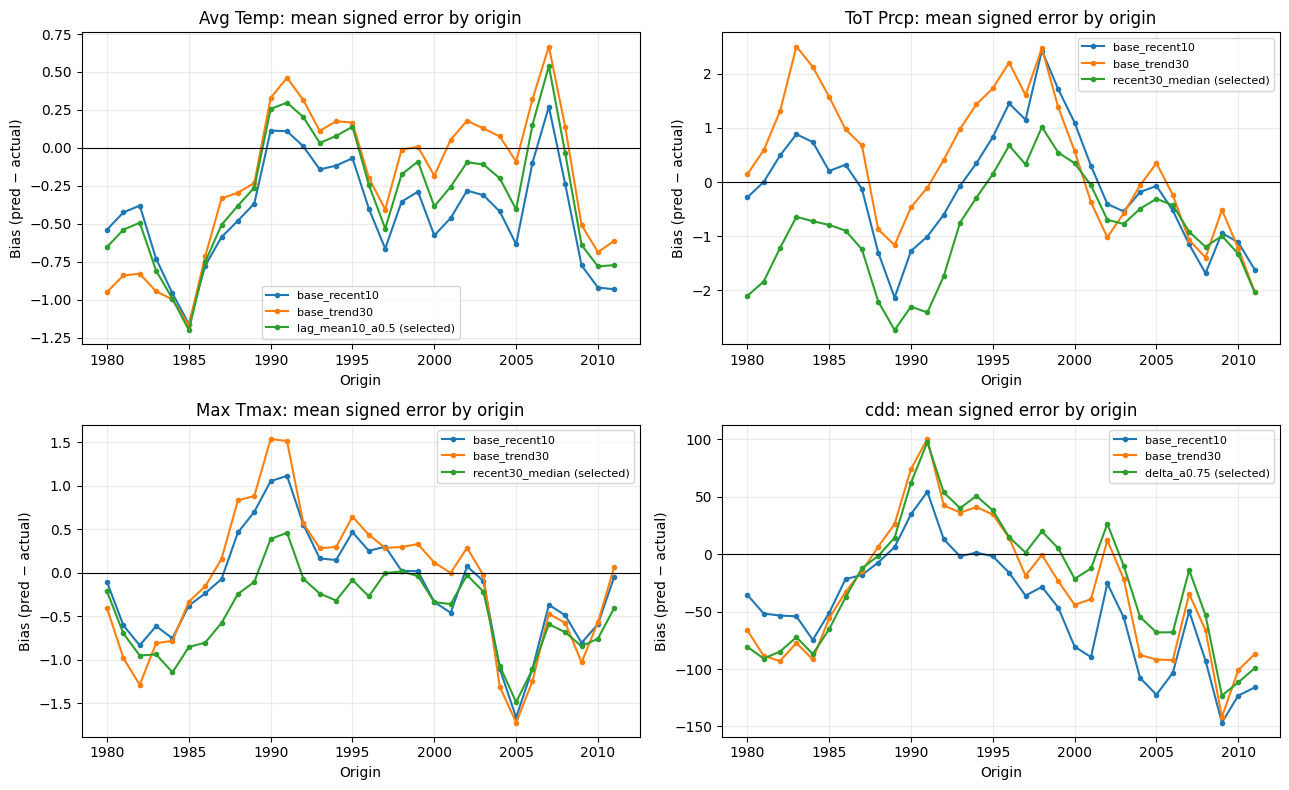

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, t in zip(axes.ravel(), TARGETS):
    for m in ["base_recent10", "base_trend30", selection[t]]:
        g = bt[(bt["target"] == t) & (bt["method"] == m)].groupby("origin")["error"].mean()
        ax.plot(g.index, g.values, marker=".", label=m + (" (selected)" if m == selection[t] else ""))
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"{t}: mean signed error by origin", xlabel="Origin", ylabel="Bias (pred − actual)")
    ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 9 · Final forecasts for 2019–2025 (origin 2018)

In [15]:
FUT = np.arange(CUTOFF + 1, CUTOFF + HORIZON + 1)
final, comp = {}, []
for t in TARGETS:
    P = predict(t, CUTOFF, final=True)
    f = P[selection[t]].copy()
    for alt in [m for m in CANDIDATES[t] if m != selection[t]] + ["base_recent10"]:
        bad = ~np.isfinite(f).all(1)
        if bad.any(): f[bad] = P[alt][bad]
    bad = ~np.isfinite(f).all(1)
    if bad.any(): f[bad] = np.nanmedian(f[~bad], axis=0)
    final[t] = f
    base = np.nanmean(np.where(STRICT[t], A[t], np.nan)[:, yidx(2009):], axis=1)
    comp.append({"target": t, "method": selection[t], "forecast − 2009–18 mean": np.nanmean(f.mean(1) - base),
                 "vs recent10": np.nanmean(f - P["base_recent10"]), "vs trend30": np.nanmean(f - P["base_trend30"])})
display(pd.DataFrame(comp).round(3))

sub = pd.DataFrame([{"city_id": c, "year": int(y), "metric": METRIC_CODE[t], "predicted_value": float(final[t][i, h])}
                    for i, c in enumerate(ids) for h, y in enumerate(FUT) for t in TARGETS])
try:
    from huggingface_hub import hf_hub_download
    tpl = pd.read_csv(hf_hub_download(TEMPLATE_REPO, "submission.csv", repo_type="dataset"))
    sub = tpl[["city_id", "year", "metric"]].merge(sub, on=["city_id", "year", "metric"], how="left", validate="one_to_one")
except Exception as e:
    print("Template not downloaded (", type(e).__name__, "); using built-in order.")
assert len(sub) == n * HORIZON * 4 and np.isfinite(sub["predicted_value"]).all()
assert not sub.duplicated(["city_id", "year", "metric"]).any()
assert (sub.loc[sub["metric"].isin(["total_precip_in", "cdd"]), "predicted_value"] >= 0).all()
sub["predicted_value"] = sub["predicted_value"].round(3)
sub.to_csv("submission.csv", index=False)
print("submission.csv:", sub.shape)

,target,method,forecast − 2009–18 mean,vs recent10,vs trend30
0,Avg Temp,lag_mean10_a0.5,0.192,0.209,-0.240
1,ToT Prcp,recent30_median,-1.377,-1.295,-1.223
2,Max Tmax,recent30_median,-0.519,-0.541,-0.720
3,cdd,delta_a0.75,23.934,28.141,-41.277


submission.csv:   0%|          | 0.00/184k [00:00<?, ?B/s]

submission.csv: (5880, 4)


## 10 · Write the curated data and documentation files

In [16]:
_, adj18, br18 = homogenised("Avg Temp", CUTOFF)
_, adjc18, brc18 = homogenised("cdd", CUTOFF)
pd.DataFrame(br18 + brc18).to_csv("data/level_shifts_at_2018.csv", index=False)

rows = []
for t in TARGETS:
    Xh, adj, _ = homogenised(t, CUTOFF)
    I, J = np.nonzero(~np.isnan(LAB[t]))
    rows.append(pd.DataFrame({"ID": ids[I], "Year": years[J], "target": t, "official": A[t][I, J],
                              "label_before_homogenisation": LAB[t][I, J], "homogenisation_adjustment": adj[I, J],
                              "label_used_at_2018": Xh[I, J], "source": SOURCE[t][I, J],
                              "missing_days": MISS_T[t][I, J]}))
pd.concat(rows).round(4).to_csv("data/labels_final.csv.gz", index=False, compression="gzip")

present = ~np.isnan(A["Avg Temp"]) | ~np.isnan(A["ToT Prcp"])
I, J = np.nonzero(present)
qf = pd.DataFrame({"ID": ids[I], "Year": years[J], "miss_tmax": miss["tmax"][I, J], "miss_tmin": miss["tmin"][I, J],
                   "miss_prcp": miss["prcp"][I, J], "miss_pair": miss["pair"][I, J],
                   "cdd_infill_added": np.round(cdd_missed[I, J], 1), "avg_temp_infill_change": np.round(avg_corr[I, J], 3)})
for t in TARGETS:
    qf[f"strict_valid_{t.lower().replace(' ', '_')}"] = STRICT[t][I, J]
sy = stuck[stuck["suspicious"]].assign(Year=lambda x: x["start"].dt.year).groupby(["ID", "Year"])["length"].sum()
qf = qf.merge(sy.rename("suspicious_stuck_tmax_days").reset_index(), on=["ID", "Year"], how="left").fillna({"suspicious_stuck_tmax_days": 0})
qf.to_csv("data/quality_flags.csv", index=False)
stuck.to_csv("data/stuck_tmax_runs.csv")
pd.concat(tables, names=["target"]).round(4).to_csv("data/final_selection_tables.csv")
pd.Series(selection, name="method").to_csv("data/final_selected_methods.csv")
print("Selected:", selection)
print("Wrote submission.csv and data/: labels_final.csv.gz, quality_flags.csv, level_shifts_at_2018.csv, "
      "stuck_tmax_runs.csv, final_selection_tables.csv, final_selected_methods.csv")

Selected: {'Avg Temp': 'lag_mean10_a0.5', 'ToT Prcp': 'recent30_median', 'Max Tmax': 'recent30_median', 'cdd': 'delta_a0.75'}
Wrote submission.csv and data/: labels_final.csv.gz, quality_flags.csv, level_shifts_at_2018.csv, stuck_tmax_runs.csv, final_selection_tables.csv, final_selected_methods.csv
